2025-07-24 17:21:55.983797: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753377716.214646      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753377716.283593      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
I0000 00:00:1753379704.576399      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1753379704.577097      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability:

Epoch 1/10


I0000 00:00:1753379710.160374     105 service.cc:148] XLA service 0x79ffb0006930 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753379710.161212     105 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1753379710.161232     105 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1753379710.413330     105 cuda_dnn.cc:529] Loaded cuDNN version 90300


  18/2539 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - accuracy: 0.5157 - loss: 0.7037

I0000 00:00:1753379712.394093     105 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2539/2539 ━━━━━━━━━━━━━━━━━━━━ 31s 11ms/step - accuracy: 0.5274 - loss: 0.6913 - val_accuracy: 0.6854 - val_loss: 0.6156
Epoch 2/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.6329 - loss: 0.6426 - val_accuracy: 0.7131 - val_loss: 0.5739
Epoch 3/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.6853 - loss: 0.5949 - val_accuracy: 0.7633 - val_loss: 0.5254
Epoch 4/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.6966 - loss: 0.5782 - val_accuracy: 0.7596 - val_loss: 0.5241
Epoch 5/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7071 - loss: 0.5658 - val_accuracy: 0.7151 - val_loss: 0.5619
Epoch 6/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7129 - loss: 0.5602 - val_accuracy: 0.7833 - val_loss: 0.4995
Epoch 7/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7143 - loss: 0.5564 - val_accuracy: 0.7476 - val_loss: 0.5251
Epoch 8/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7135 - loss: 0.55

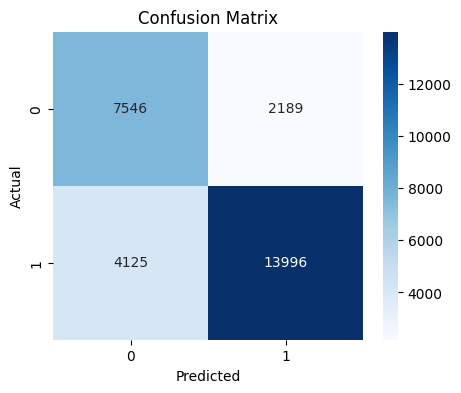


Classification Report:
               precision    recall  f1-score   support

           0     0.6466    0.7751    0.7050      9735
           1     0.8648    0.7724    0.8160     18121

    accuracy                         0.7733     27856
   macro avg     0.7557    0.7738    0.7605     27856
weighted avg     0.7885    0.7733    0.7772     27856

Sensitivity (Recall): 0.7724
Specificity: 0.7751


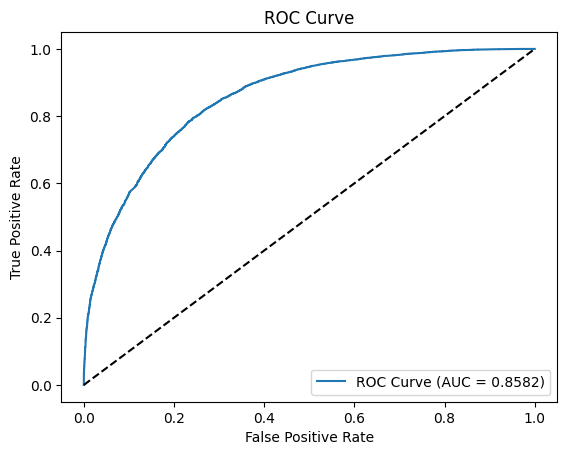

In [1]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, GlobalMaxPooling1D, Dropout, Input
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs Without Header and Skip First Row
train_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_train.csv', header=None, skiprows=1)
val_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_val.csv', header=None, skiprows=1)
test_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_test.csv', header=None, skiprows=1)

# 📝 Step 3: Assign Column Names
column_names = ['text', 'features', 'level']
train_df.columns = column_names
val_df.columns = column_names
test_df.columns = column_names

# 🧹 Step 4: Remove invalid rows where 'features' is not a list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['features'].apply(is_valid_feature)]
val_df = val_df[val_df['features'].apply(is_valid_feature)]
test_df = test_df[test_df['features'].apply(is_valid_feature)]

# ✅ Step 5: Convert strings to array safely
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['features']))
y_train = train_df['level'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['features']))
y_val = val_df['level'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['features']))
y_test = test_df['level'].astype(int).values

# 🔁 Step 6: Reshape for CNN input
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# 🧠 Step 7: CNN Model
model = Sequential([
    Input(shape=(X_train.shape[1], 1)),
    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 🚀 Step 8: Train the Model
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=64)

# 📊 Step 9: Evaluate the Model
y_pred_prob = model.predict(X_test).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", acc)

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


Random Forest

In [5]:
# 📁 Create directory for saving results
import os
os.makedirs("cnn_results", exist_ok=True)

# ✅ Save Accuracy
with open("cnn_results/accuracy.txt", "w") as f:
    f.write(f"Accuracy: {acc:.4f}\n")

# ✅ Save Confusion Matrix
cm_df = pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Pred 0", "Pred 1"])
cm_df.to_csv("cnn_results/confusion_matrix.csv")

# ✅ Save Classification Report
report = classification_report(y_test, y_pred, digits=4, output_dict=True)
pd.DataFrame(report).transpose().to_csv("cnn_results/classification_report.csv")

# ✅ Save Sensitivity & Specificity
with open("cnn_results/metrics.txt", "w") as f:
    f.write(f"Sensitivity (Recall): {sensitivity:.4f}\n")
    f.write(f"Specificity: {specificity:.4f}\n")
    f.write(f"AUC Score: {roc_auc:.4f}\n")

# ✅ Save ROC Curve Plot
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.savefig("cnn_results/roc_curve.png")
plt.close()

print("✅ All CNN evaluation results saved in: cnn_results/")


✅ All CNN evaluation results saved in: cnn_results/


✅ Accuracy: 0.9813684663986215


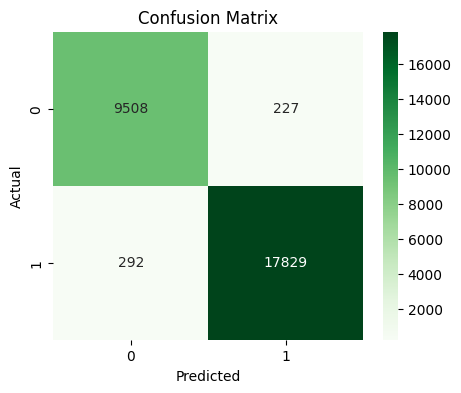


Classification Report:
               precision    recall  f1-score   support

           0     0.9702    0.9767    0.9734      9735
           1     0.9874    0.9839    0.9857     18121

    accuracy                         0.9814     27856
   macro avg     0.9788    0.9803    0.9795     27856
weighted avg     0.9814    0.9814    0.9814     27856

Sensitivity (Recall): 0.9839
Specificity: 0.9767


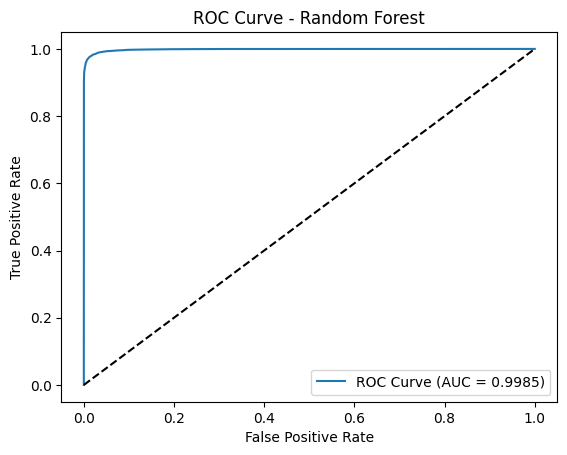

In [4]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs Without Header and Skip First Row
train_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_train.csv', header=None, skiprows=1)
val_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_val.csv', header=None, skiprows=1)
test_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_test.csv', header=None, skiprows=1)

# 📝 Step 3: Assign Column Names
column_names = ['text', 'features', 'level']
train_df.columns = column_names
val_df.columns = column_names
test_df.columns = column_names

# 🧹 Step 4: Remove invalid rows where 'features' is not a list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['features'].apply(is_valid_feature)]
val_df = val_df[val_df['features'].apply(is_valid_feature)]
test_df = test_df[test_df['features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['features']))
y_train = train_df['level'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['features']))
y_val = val_df['level'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['features']))
y_test = test_df['level'].astype(int).values

# 🧠 Step 6: Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate the Model
y_pred = rf_model.predict(X_test)
y_pred_prob = rf_model.predict_proba(X_test)[:, 1]

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", acc)

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend(loc='lower right')
plt.show()


In [6]:
# 📁 Create directory to store RF results
os.makedirs("rf_results", exist_ok=True)

# ✅ Save Accuracy
with open("rf_results/accuracy.txt", "w") as f:
    f.write(f"Accuracy: {acc:.4f}\n")

# ✅ Save Confusion Matrix
cm_df = pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Pred 0", "Pred 1"])
cm_df.to_csv("rf_results/confusion_matrix.csv")

# ✅ Save Classification Report
report = classification_report(y_test, y_pred, digits=4, output_dict=True)
pd.DataFrame(report).transpose().to_csv("rf_results/classification_report.csv")

# ✅ Save Sensitivity & Specificity
with open("rf_results/metrics.txt", "w") as f:
    f.write(f"Sensitivity (Recall): {sensitivity:.4f}\n")
    f.write(f"Specificity: {specificity:.4f}\n")
    f.write(f"AUC Score: {roc_auc:.4f}\n")

# ✅ Save ROC Curve Plot
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend(loc='lower right')
plt.savefig("rf_results/roc_curve.png")
plt.close()

print("✅ All Random Forest evaluation results saved in: rf_results/")


✅ All Random Forest evaluation results saved in: rf_results/


Decision Tree

✅ Accuracy: 0.9667935094773119


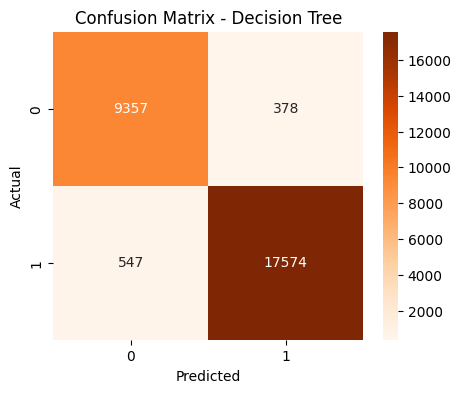


Classification Report:
               precision    recall  f1-score   support

           0     0.9448    0.9612    0.9529      9735
           1     0.9789    0.9698    0.9744     18121

    accuracy                         0.9668     27856
   macro avg     0.9619    0.9655    0.9636     27856
weighted avg     0.9670    0.9668    0.9669     27856

Sensitivity (Recall): 0.9698
Specificity: 0.9612


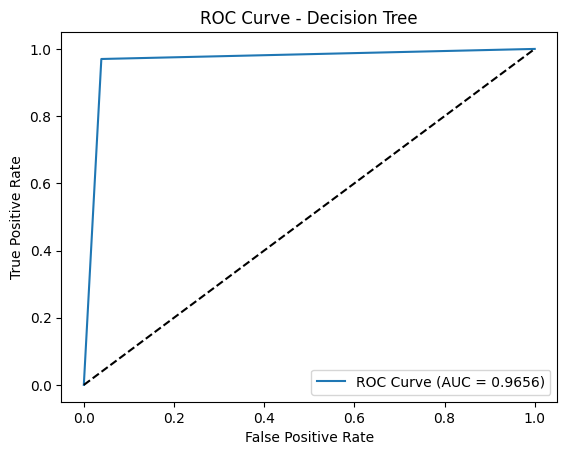

In [7]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs Without Header and Skip First Row
train_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_train.csv', header=None, skiprows=1)
val_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_val.csv', header=None, skiprows=1)
test_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_test.csv', header=None, skiprows=1)

# 📝 Step 3: Assign Column Names
column_names = ['text', 'features', 'level']
train_df.columns = column_names
val_df.columns = column_names
test_df.columns = column_names

# 🧹 Step 4: Remove invalid rows where 'features' is not a list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['features'].apply(is_valid_feature)]
val_df = val_df[val_df['features'].apply(is_valid_feature)]
test_df = test_df[test_df['features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['features']))
y_train = train_df['level'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['features']))
y_val = val_df['level'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['features']))
y_test = test_df['level'].astype(int).values

# 🧠 Step 6: Train Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate the Model
y_pred = dt_model.predict(X_test)
y_pred_prob = dt_model.predict_proba(X_test)[:, 1]

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", acc)

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree')
plt.legend(loc='lower right')
plt.show()


In [8]:
import os

# Create output directory
os.makedirs('outputs_decision_tree', exist_ok=True)

# Save classification report to text file
with open('outputs_decision_tree/classification_report.txt', 'w') as f:
    f.write(f"Accuracy: {acc:.4f}\n")
    f.write(f"Sensitivity (Recall): {sensitivity:.4f}\n")
    f.write(f"Specificity: {specificity:.4f}\n\n")
    f.write("Classification Report:\n")
    f.write(classification_report(y_test, y_pred, digits=4))

# Save confusion matrix as image
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig('outputs_decision_tree/confusion_matrix.png')
plt.close()

# Save ROC curve
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('outputs_decision_tree/roc_curve.png')
plt.close()


In [ ]:
Naive Bias

✅ Accuracy: 0.7420304422745548


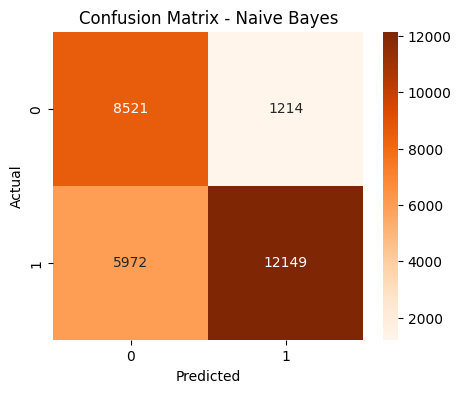


Classification Report:
               precision    recall  f1-score   support

           0     0.5879    0.8753    0.7034      9735
           1     0.9092    0.6704    0.7718     18121

    accuracy                         0.7420     27856
   macro avg     0.7485    0.7729    0.7376     27856
weighted avg     0.7969    0.7420    0.7479     27856

Sensitivity (Recall): 0.6704
Specificity: 0.8753


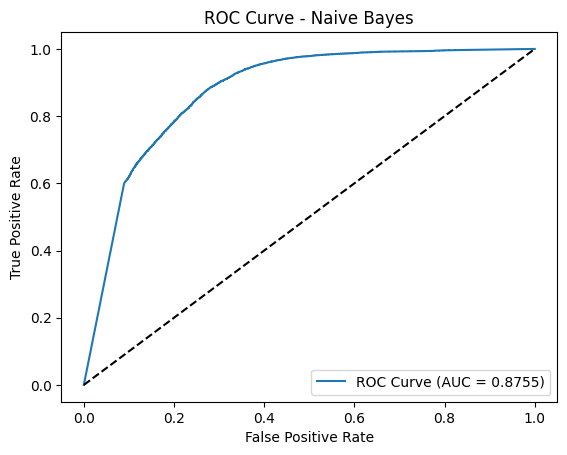

In [9]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs Without Header and Skip First Row
train_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_train.csv', header=None, skiprows=1)
val_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_val.csv', header=None, skiprows=1)
test_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_test.csv', header=None, skiprows=1)

# 📝 Step 3: Assign Column Names
column_names = ['text', 'features', 'level']
train_df.columns = column_names
val_df.columns = column_names
test_df.columns = column_names

# 🧹 Step 4: Remove invalid rows where 'features' is not a list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['features'].apply(is_valid_feature)]
val_df = val_df[val_df['features'].apply(is_valid_feature)]
test_df = test_df[test_df['features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['features']))
y_train = train_df['level'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['features']))
y_val = val_df['level'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['features']))
y_test = test_df['level'].astype(int).values

# 🧠 Step 6: Train Naive Bayes Classifier
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate the Model
y_pred = nb_model.predict(X_test)
y_pred_prob = nb_model.predict_proba(X_test)[:, 1]

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", acc)

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Naive Bayes')
plt.legend(loc='lower right')
plt.show()


In [11]:
# 💾 Save Classification Report + Accuracy + Sensitivity + Specificity
with open("naive_bayes_report.txt", "w") as f:
    f.write(f"Accuracy: {acc:.4f}\n")
    f.write(f"Sensitivity (Recall): {sensitivity:.4f}\n")
    f.write(f"Specificity: {specificity:.4f}\n\n")
    f.write("Classification Report:\n")
    f.write(classification_report(y_test, y_pred, digits=4))

# 💾 Save Confusion Matrix Plot
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("naive_bayes_confusion_matrix.png")
plt.close()

# 💾 Save ROC Curve Plot
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Naive Bayes')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("naive_bayes_roc_curve.png")
plt.close()


Logistic Regration

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


✅ Accuracy: 0.9797889144170018


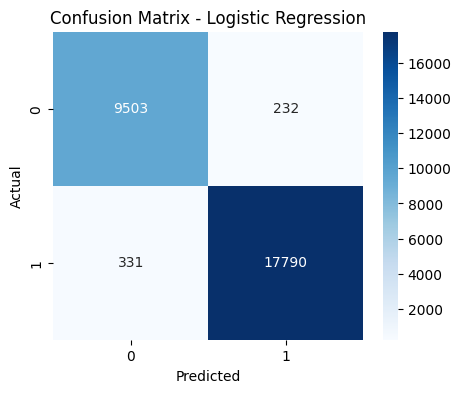


Classification Report:
               precision    recall  f1-score   support

           0     0.9663    0.9762    0.9712      9735
           1     0.9871    0.9817    0.9844     18121

    accuracy                         0.9798     27856
   macro avg     0.9767    0.9790    0.9778     27856
weighted avg     0.9799    0.9798    0.9798     27856

Sensitivity (Recall): 0.9817
Specificity: 0.9762


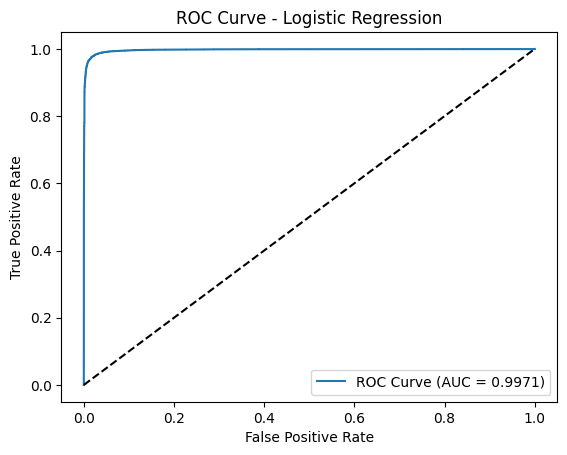

In [12]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs Without Header and Skip First Row
train_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_train.csv', header=None, skiprows=1)
val_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_val.csv', header=None, skiprows=1)
test_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_test.csv', header=None, skiprows=1)

# 📝 Step 3: Assign Column Names
column_names = ['text', 'features', 'level']
train_df.columns = column_names
val_df.columns = column_names
test_df.columns = column_names

# 🧹 Step 4: Remove invalid rows where 'features' is not a list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['features'].apply(is_valid_feature)]
val_df = val_df[val_df['features'].apply(is_valid_feature)]
test_df = test_df[test_df['features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['features']))
y_train = train_df['level'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['features']))
y_val = val_df['level'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['features']))
y_test = test_df['level'].astype(int).values

# 🧠 Step 6: Train Logistic Regression Classifier
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate the Model
y_pred = lr_model.predict(X_test)
y_pred_prob = lr_model.predict_proba(X_test)[:, 1]

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", acc)

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend(loc='lower right')
plt.show()


SVM Linear

In [ ]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs Without Header and Skip First Row
train_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_train.csv', header=None, skiprows=1)
val_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_val.csv', header=None, skiprows=1)
test_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_test.csv', header=None, skiprows=1)

# 📝 Step 3: Assign Column Names
column_names = ['text', 'features', 'level']
train_df.columns = column_names
val_df.columns = column_names
test_df.columns = column_names

# 🧹 Step 4: Remove invalid rows where 'features' is not a list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['features'].apply(is_valid_feature)]
val_df = val_df[val_df['features'].apply(is_valid_feature)]
test_df = test_df[test_df['features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['features']))
y_train = train_df['level'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['features']))
y_val = val_df['level'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['features']))
y_test = test_df['level'].astype(int).values

# 🧠 Step 6: Train Linear SVM
svm_model = SVC(kernel='linear', probability=True, random_state=42)
svm_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate the Model
y_pred = svm_model.predict(X_test)
y_pred_prob = svm_model.predict_proba(X_test)[:, 1]

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", acc)

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
plt.title("Confusion Matrix - SVM (Linear)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - SVM (Linear)')
plt.legend(loc='lower right')
plt.show()
